In [1]:

import os

DATA_ROOT = "/kaggle/input"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    # Limit output to avoid printing every image filename
    if level <= 3:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:8]:
            print(f"{indent}  {file}")

        if len(files) > 8:
            print(f"{indent}  ... and {len(files) - 8} more files")


input/
  competitions/
    industrial-surface-defect-detection/
      public/
        sample_submission.csv
        train.csv


In [2]:

import os
import pandas as pd

csv_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", len(csv_files))

for path in csv_files:
    print("\n" + "=" * 70)
    print("FILE:", path)

    try:
        df = pd.read_csv(path, nrows=5)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print("Could not read:", e)


CSV files found: 2

FILE: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
 ID   image_id defect_type mask_rle
  1 WAFNKCRR7Q    defect_a         
  2 WAFNKCRR7Q    defect_b         
  3 WAFNKCRR7Q    defect_c         

FILE: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
Columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']
  image_id defect_type                                                                                                                                                                                                                                                                                                                                                                                                                                                                              mask_rle  width  height
4S22I7SA34    defect

In [3]:

import os
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection"

# Locate the CSV files automatically
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f in ["train.csv", "sample_submission.csv"]:
            print(os.path.join(root, f))

TRAIN_CSV = os.path.join(DATA_DIR, "public", "train.csv")
SUB_CSV = os.path.join(DATA_DIR, "public", "sample_submission.csv")

train_df = pd.read_csv(TRAIN_CSV)

# Convert missing masks to empty strings
train_df["mask_rle"] = train_df["mask_rle"].fillna("")

sample_df = pd.read_csv(SUB_CSV)

print("\nTrain shape:", train_df.shape)
print("Submission shape:", sample_df.shape)

print("\nDefect distribution:")
print(train_df["defect_type"].value_counts())

print("\nEmpty masks:", train_df["mask_rle"].isna().sum())
print("Non-empty masks:", train_df["mask_rle"].notna().sum())

print("\nImage dimensions:")
print(train_df[["width", "height"]].drop_duplicates())

print("\nUnique training images:", train_df["image_id"].nunique())
print("Unique test images:", sample_df["image_id"].nunique())

print("\nDataset files and folders:")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (level + 1) + f)
        if len(files) > 5:
            print("  " * (level + 1) + f"... {len(files)-5} more files")


/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv

Train shape: (45572, 5)
Submission shape: (12000, 4)

Defect distribution:
defect_type
defect_a    11393
defect_b    11393
defect_c    11393
defect_d    11393
Name: count, dtype: int64

Empty masks: 0
Non-empty masks: 45572

Image dimensions:
   width  height
0    800     128

Unique training images: 11393
Unique test images: 3000

Dataset files and folders:
industrial-surface-defect-detection/
  public/
    sample_submission.csv
    train.csv
    test/
      LZ46LTL6O2.jpg
      13H1VTAZ42.jpg
      G0DWU2GK1L.jpg
      CVPHC0DT1P.jpg
      90XJFQDL7G.jpg
      ... 2995 more files
    train/
      I2P3TOD3FY.jpg
      2GYBBED7DJ.jpg
      DFRBLMRLQ9.jpg
      I7GTCUX6HT.jpg
      OMXK41V3QA.jpg
      ... 11388 more files


In [4]:
print("Training dataset shape:", train_df.shape)

print("\nNull values in each column:")
print(train_df.isnull().sum())

print("\nEmpty masks:", (train_df["mask_rle"] == "").sum())
print("Non-empty masks:", (train_df["mask_rle"] != "").sum())

print("\nFirst 10 mask values:")
print([repr(x) for x in train_df["mask_rle"].head(10)])

Training dataset shape: (45572, 5)

Null values in each column:
image_id       0
defect_type    0
mask_rle       0
width          0
height         0
dtype: int64

Empty masks: 38371
Non-empty masks: 7201

First 10 mask values:
["'7255 6 7377 12 7505 12 7633 12 7762 11 7890 11 8018 11 8146 11 19503 28 19631 32 19759 36 19886 41 20014 45 20142 49 20269 53 20397 52 20525 52 20654 13 20673 32 20785 8 20807 25 20915 4 20941 19 21075 13 21211 4 21362 15 21476 29 21604 29 21732 29 21859 30 21987 30 22115 30 22242 27 22370 16 22434 14 22497 15 22561 19 22625 7 22689 19 22753 1 22817 19 22945 19 23073 19 23201 19 23328 20 23461 15 47408 4 47526 14 47654 14 47782 14 47910 14 48038 14 48166 11 48294 2'", "''", "''", "''", "''", "''", "''", "''", "''", "''"]


Image ID: 4S22I7SA34
Image shape: (128, 800, 3)
Defect category: defect_a
Mask shape: (128, 800)
Defect pixels: 1100


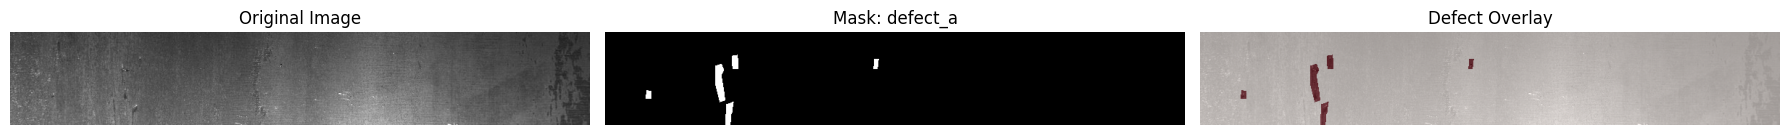

In [5]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection"
TRAIN_DIR = os.path.join(DATA_DIR, "public", "train")
TRAIN_CSV = os.path.join(DATA_DIR, "public", "train.csv")

df = pd.read_csv(TRAIN_CSV)

def decode_rle(rle, height, width):
    """Decode a 1-indexed RLE mask using column-major order."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")


# Select an image with at least one annotated defect
row = df[df["mask_rle"].notna()].iloc[0]
image_id = row["image_id"]

image_path = os.path.join(TRAIN_DIR, image_id + ".jpg")
image = np.array(Image.open(image_path).convert("RGB"))

height = int(row["height"])
width = int(row["width"])
mask = decode_rle(row["mask_rle"], height, width)

print("Image ID:", image_id)
print("Image shape:", image.shape)
print("Defect category:", row["defect_type"])
print("Mask shape:", mask.shape)
print("Defect pixels:", int(mask.sum()))

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
plt.title(f"Mask: {row['defect_type']}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.55, vmin=0, vmax=1)
plt.title("Defect Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:

summary = (
    df.assign(has_defect=df["mask_rle"].notna())
      .groupby("defect_type")
      .agg(
          total_rows=("image_id", "size"),
          images_with_defect=("has_defect", "sum"),
          unique_images=("image_id", "nunique")
      )
)

summary["empty_masks"] = (
    summary["total_rows"] - summary["images_with_defect"]
)

print(summary)


             total_rows  images_with_defect  unique_images  empty_masks
defect_type                                                            
defect_a          11393                1081          11393        10312
defect_b          11393                 313          11393        11080
defect_c          11393                4100          11393         7293
defect_d          11393                1707          11393         9686


In [7]:

from sklearn.model_selection import train_test_split

# Keep the four defect categories in a fixed order
DEFECT_TYPES = ["defect_a", "defect_b", "defect_c", "defect_d"]

# One row per image, preserving all four annotations in df
image_ids = df["image_id"].drop_duplicates().to_numpy()

train_ids, val_ids = train_test_split(
    image_ids,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

print("Total images:", len(image_ids))
print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Overlap:", len(set(train_ids) & set(val_ids)))

assert len(set(train_ids) & set(val_ids)) == 0


Total images: 11393
Training images: 9684
Validation images: 1709
Overlap: 0


In [8]:

import os
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf

DATA_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection"
TRAIN_DIR = os.path.join(DATA_DIR, "public", "train")
TEST_DIR = os.path.join(DATA_DIR, "public", "test")

HEIGHT, WIDTH = 128, 800
NUM_CLASSES = 4
BATCH_SIZE = 8

# Map each defect category to its output channel
DEFECT_TO_CHANNEL = {
    name: i for i, name in enumerate(DEFECT_TYPES)
}

# Store the annotations for quick lookup
annotations = {}

for row in df.itertuples(index=False):
    key = (row.image_id, row.defect_type)
    annotations[key] = row.mask_rle


def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode the competition's column-major RLE mask."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((height, width), order="F")

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")


def load_image(image_id):
    path = os.path.join(TRAIN_DIR, image_id + ".jpg")
    with Image.open(path) as im:
        image = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0

    return image


def load_masks(image_id):
    masks = np.zeros(
        (HEIGHT, WIDTH, NUM_CLASSES),
        dtype=np.float32
    )

    for defect_type, channel in DEFECT_TO_CHANNEL.items():
        rle = annotations.get((image_id, defect_type))

        if rle is not None and not pd.isna(rle):
            masks[:, :, channel] = decode_rle(rle)

    return masks


class DefectSequence(tf.keras.utils.Sequence):
    def __init__(self, ids, batch_size=BATCH_SIZE, shuffle=True):
        super().__init__()
        self.ids = np.asarray(ids)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.ids))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.ids) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch_ids = self.ids[batch_indices]

        X = np.empty(
            (len(batch_ids), HEIGHT, WIDTH, 3),
            dtype=np.float32
        )
        Y = np.zeros(
            (len(batch_ids), HEIGHT, WIDTH, NUM_CLASSES),
            dtype=np.float32
        )

        for i, image_id in enumerate(batch_ids):
            X[i] = load_image(image_id)
            Y[i] = load_masks(image_id)

        return X, Y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


train_gen = DefectSequence(train_ids, shuffle=True)
val_gen = DefectSequence(val_ids, shuffle=False)

# Verify one batch before training
X_batch, Y_batch = train_gen[0]

print("Input batch shape:", X_batch.shape)
print("Target batch shape:", Y_batch.shape)
print("Input range:", X_batch.min(), X_batch.max())
print("Target values:", np.unique(Y_batch))
print("Positive pixels per channel:", Y_batch.sum(axis=(0, 1, 2)))


Input batch shape: (8, 128, 800, 3)
Target batch shape: (8, 128, 800, 4)
Input range: 0.0 1.0
Target values: [0. 1.]
Positive pixels per channel: [  139.     0. 17559.  3075.]


In [9]:

channel_names = ["defect_a", "defect_b", "defect_c", "defect_d"]

positive_images = np.zeros(4, dtype=np.int64)
positive_pixels = np.zeros(4, dtype=np.int64)

for batch_idx in range(min(10, len(train_gen))):
    X, Y = train_gen[batch_idx]

    positive_pixels += Y.sum(axis=(0, 1, 2)).astype(np.int64)
    positive_images += (Y.sum(axis=(1, 2)) > 0).sum(axis=0).astype(np.int64)

print("Results across up to 10 batches:")
for i, name in enumerate(channel_names):
    print(
        f"{name}: images with masks={positive_images[i]}, "
        f"positive pixels={positive_pixels[i]}"
    )


Results across up to 10 batches:
defect_a: images with masks=5, positive pixels=3011
defect_b: images with masks=2, positive pixels=676
defect_c: images with masks=25, positive pixels=109102
defect_d: images with masks=12, positive pixels=90249


In [10]:

# import tensorflow as tf
# from tensorflow.keras import layers, Model

# def conv_block(x, filters):
#     x = layers.Conv2D(
#         filters, 3, padding="same", activation="relu"
#     )(x)
#     x = layers.BatchNormalization()(x)

#     x = layers.Conv2D(
#         filters, 3, padding="same", activation="relu"
#     )(x)
#     x = layers.BatchNormalization()(x)

#     return x


# def build_unet(input_shape=(128, 800, 3), num_classes=4):
#     inputs = layers.Input(shape=input_shape)

#     # Encoder
#     c1 = conv_block(inputs, 16)
#     p1 = layers.MaxPooling2D()(c1)

#     c2 = conv_block(p1, 32)
#     p2 = layers.MaxPooling2D()(c2)

#     c3 = conv_block(p2, 64)
#     p3 = layers.MaxPooling2D()(c3)

#     c4 = conv_block(p3, 128)
#     p4 = layers.MaxPooling2D()(c4)

#     # Bottleneck
#     b = conv_block(p4, 256)

#     # Decoder
#     u4 = layers.Conv2DTranspose(
#         128, 2, strides=2, padding="same"
#     )(b)
#     u4 = layers.Concatenate()([u4, c4])
#     c5 = conv_block(u4, 128)

#     u3 = layers.Conv2DTranspose(
#         64, 2, strides=2, padding="same"
#     )(c5)
#     u3 = layers.Concatenate()([u3, c3])
#     c6 = conv_block(u3, 64)

#     u2 = layers.Conv2DTranspose(
#         32, 2, strides=2, padding="same"
#     )(c6)
#     u2 = layers.Concatenate()([u2, c2])
#     c7 = conv_block(u2, 32)

#     u1 = layers.Conv2DTranspose(
#         16, 2, strides=2, padding="same"
#     )(c7)
#     u1 = layers.Concatenate()([u1, c1])
#     c8 = conv_block(u1, 16)

#     outputs = layers.Conv2D(
#         num_classes, 1, activation="sigmoid"
#     )(c8)

#     return Model(inputs, outputs, name="SurfaceGuard_UNet")


# model = build_unet()

# model.summary()
# print("Input shape:", model.input_shape)
# print("Output shape:", model.output_shape)
# print("Parameters:", f"{model.count_params():,}")


In [11]:

# def dice_loss(y_true, y_pred, smooth=1.0):
#     y_true = tf.cast(y_true, tf.float32)
#     y_pred = tf.cast(y_pred, tf.float32)

#     intersection = tf.reduce_sum(
#         y_true * y_pred, axis=[1, 2]
#     )
#     denominator = tf.reduce_sum(
#         y_true + y_pred, axis=[1, 2]
#     )

#     dice = (2.0 * intersection + smooth) / (
#         denominator + smooth
#     )

#     # Average over images and defect channels
#     return 1.0 - tf.reduce_mean(dice)


# def combined_loss(y_true, y_pred):
#     bce = tf.reduce_mean(
#         tf.keras.losses.binary_crossentropy(y_true, y_pred)
#     )
#     return bce + dice_loss(y_true, y_pred)


# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
#     loss=combined_loss
# )

# print("Model compiled successfully.")


In [12]:

import torch
import torchvision
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        )
    )
else:
    print("Using CPU. Enable a GPU in Kaggle Settings if available.")

print("\nDataset variables:")
print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Image size:", HEIGHT, "x", WIDTH)
print("Defect categories:", DEFECT_TYPES)


PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56

Dataset variables:
Training images: 9684
Validation images: 1709
Image size: 128 x 800
Defect categories: ['defect_a', 'defect_b', 'defect_c', 'defect_d']


In [13]:

import os
import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

DATA_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection"
TRAIN_DIR = os.path.join(DATA_DIR, "public", "train")

HEIGHT, WIDTH = 128, 800
DEFECT_TYPES = ["defect_a", "defect_b", "defect_c", "defect_d"]

DEFECT_TO_CHANNEL = {
    name: i for i, name in enumerate(DEFECT_TYPES)
}

# Store each image/category annotation for fast lookup
annotations = {
    (row.image_id, row.defect_type): row.mask_rle
    for row in df.itertuples(index=False)
}


def decode_rle(rle, height=HEIGHT, width=WIDTH):
    """Decode 1-indexed, column-major run-length encoding."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape(height, width, order="F")

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape(height, width, order="F")


class SurfaceDefectDataset(Dataset):
    def __init__(self, image_ids, image_dir, augment=False):
        self.image_ids = list(image_ids)
        self.image_dir = image_dir
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_path = os.path.join(
            self.image_dir, image_id + ".jpg"
        )

        with Image.open(image_path) as im:
            image = np.asarray(
                im.convert("RGB"), dtype=np.float32
            ) / 255.0

        masks = np.zeros(
            (HEIGHT, WIDTH, len(DEFECT_TYPES)),
            dtype=np.float32
        )

        for defect_type, channel in DEFECT_TO_CHANNEL.items():
            rle = annotations.get((image_id, defect_type))

            if rle is not None and not pd.isna(rle):
                masks[:, :, channel] = decode_rle(rle)

        # Convert HWC arrays to PyTorch CHW tensors
        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        )
        masks = torch.from_numpy(
            np.ascontiguousarray(masks.transpose(2, 0, 1))
        )

        # Horizontal flip: apply the same transformation to image and masks
        if self.augment and torch.rand(()) < 0.5:
            image = torch.flip(image, dims=[2])
            masks = torch.flip(masks, dims=[2])

        return image, masks


BATCH_SIZE = 4

train_dataset = SurfaceDefectDataset(
    train_ids, TRAIN_DIR, augment=True
)
val_dataset = SurfaceDefectDataset(
    val_ids, TRAIN_DIR, augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training images: 9684
Validation images: 1709
Training batches: 2421
Validation batches: 428


In [14]:

images, masks = next(iter(train_loader))

print("Image tensor shape:", images.shape)
print("Mask tensor shape:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))
print(
    "Positive pixels per class:",
    masks.sum(dim=(0, 2, 3)).tolist()
)

assert images.shape == (BATCH_SIZE, 3, HEIGHT, WIDTH)
assert masks.shape == (BATCH_SIZE, 4, HEIGHT, WIDTH)
assert torch.all((masks == 0) | (masks == 1))

print("Dataset verification passed.")


Image tensor shape: torch.Size([4, 3, 128, 800])
Mask tensor shape: torch.Size([4, 4, 128, 800])
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: 0.0 1.0
Mask values: tensor([0., 1.])
Positive pixels per class: [0.0, 0.0, 496.0, 0.0]
Dataset verification passed.


In [15]:

import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    """Two convolution layers with BatchNorm and ReLU."""

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNetScratch(nn.Module):
    """U-Net for four-channel industrial defect segmentation."""

    def __init__(self, in_channels=3, num_classes=4, base=16):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(in_channels, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 8)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck
        self.bottleneck = ConvBlock(base * 8, base * 16)

        # Decoder: transposed convolutions and skip connections
        self.up4 = nn.ConvTranspose2d(
            base * 16, base * 8, kernel_size=2, stride=2
        )
        self.dec4 = ConvBlock(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(
            base * 8, base * 4, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(
            base * 4, base * 2, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(
            base * 2, base, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(base * 2, base)

        # Raw logits: sigmoid will be applied during inference
        self.output = nn.Conv2d(
            base, num_classes, kernel_size=1
        )

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


# Initialize all weights from scratch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNetScratch(
    in_channels=3,
    num_classes=4,
    base=16
).to(device)

print("Device:", device)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print(model)


Device: cuda
Model parameters: 1,942,628
UNetScratch(
  (enc1): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (block): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )

In [16]:

model.eval()

with torch.no_grad():
    sample_images = images[:1].to(device)
    logits = model(sample_images)

print("Input shape:", tuple(sample_images.shape))
print("Output logits shape:", tuple(logits.shape))
print("Output dtype:", logits.dtype)

assert logits.shape == (1, 4, 128, 800)

print("U-Net architecture verification passed.")


Input shape: (1, 3, 128, 800)
Output logits shape: (1, 4, 128, 800)
Output dtype: torch.float32
U-Net architecture verification passed.


In [17]:

import torch
import torch.nn as nn

def dice_loss_logits(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(2, 3))
    denominator = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

    dice = (2.0 * intersection + smooth) / (denominator + smooth)

    return 1.0 - dice.mean()


class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        dice = dice_loss_logits(logits, targets)

        return self.bce_weight * bce_loss + (
            1.0 - self.bce_weight
        ) * dice


criterion = BCEDiceLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])


Loss function: BCEDiceLoss(
  (bce): BCEWithLogitsLoss()
)
Optimizer: AdamW
Initial learning rate: 0.001


In [18]:

# import copy
# import os
# from tqdm.auto import tqdm

# CHECKPOINT_PATH = "/kaggle/working/unet_scratch_best.pth"
# EPOCHS = 5

# best_val_loss = float("inf")
# history = {"train_loss": [], "val_loss": []}

# for epoch in range(EPOCHS):
#     # Training
#     model.train()
#     train_loss_sum = 0.0

#     progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

#     for batch_images, batch_masks in progress:
#         batch_images = batch_images.to(device, non_blocking=True)
#         batch_masks = batch_masks.to(device, non_blocking=True)

#         optimizer.zero_grad(set_to_none=True)

#         logits = model(batch_images)
#         loss = criterion(logits, batch_masks)

#         loss.backward()
#         optimizer.step()

#         train_loss_sum += loss.item()
#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = train_loss_sum / len(train_loader)

#     # Validation
#     model.eval()
#     val_loss_sum = 0.0

#     with torch.no_grad():
#         for batch_images, batch_masks in tqdm(
#             val_loader, desc="Validation"
#         ):
#             batch_images = batch_images.to(device, non_blocking=True)
#             batch_masks = batch_masks.to(device, non_blocking=True)

#             logits = model(batch_images)
#             loss = criterion(logits, batch_masks)

#             val_loss_sum += loss.item()

#     val_loss = val_loss_sum / len(val_loader)

#     history["train_loss"].append(train_loss)
#     history["val_loss"].append(val_loss)

#     print(
#         f"Epoch {epoch+1}: "
#         f"train_loss={train_loss:.5f}, "
#         f"val_loss={val_loss:.5f}"
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss

#         torch.save(
#             {
#                 "epoch": epoch + 1,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "val_loss": val_loss,
#                 "defect_types": DEFECT_TYPES
#             },
#             CHECKPOINT_PATH
#         )

#         print("Saved new best checkpoint:", CHECKPOINT_PATH)

# print("\nBest validation loss:", best_val_loss)

In [19]:

# Recreate loaders without multiprocessing workers
BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("DataLoaders recreated with num_workers=0")


Training batches: 2421
Validation batches: 428
DataLoaders recreated with num_workers=0


In [20]:

# CHECKPOINT_PATH = "/kaggle/working/unet_scratch_best.pth"

# checkpoint = torch.load(
#     CHECKPOINT_PATH,
#     map_location=device,
#     weights_only=True
# )

# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# print("Best checkpoint loaded successfully.")
# print("Best epoch:", checkpoint["epoch"])
# print("Best validation loss:", checkpoint["val_loss"])


In [21]:

# import numpy as np
# import torch
# from tqdm.auto import tqdm

# def evaluate_dice(model, loader, device, threshold=0.5, smooth=1e-6):
#     model.eval()

#     # Accumulate pixel counts over the entire validation set
#     intersection = torch.zeros(4, dtype=torch.float64)
#     pred_sum = torch.zeros(4, dtype=torch.float64)
#     target_sum = torch.zeros(4, dtype=torch.float64)

#     with torch.no_grad():
#         for images, masks in tqdm(loader, desc="Evaluating Dice"):
#             images = images.to(device)
#             masks = masks.to(device)

#             probabilities = torch.sigmoid(model(images))
#             predictions = probabilities >= threshold

#             intersection += (predictions & (masks > 0.5)).sum(
#                 dim=(0, 2, 3)
#             ).cpu().double()

#             pred_sum += predictions.sum(
#                 dim=(0, 2, 3)
#             ).cpu().double()

#             target_sum += (masks > 0.5).sum(
#                 dim=(0, 2, 3)
#             ).cpu().double()

#     dice = (
#         2 * intersection + smooth
#     ) / (
#         pred_sum + target_sum + smooth
#     )

#     for i, name in enumerate(DEFECT_TYPES):
#         print(
#             f"{name}: Dice={dice[i].item():.5f}, "
#             f"predicted_pixels={int(pred_sum[i])}, "
#             f"true_pixels={int(target_sum[i])}"
#         )

#     print("Macro Dice:", dice.mean().item())
#     return dice


# dice_scores = evaluate_dice(
#     model, val_loader, device, threshold=0.5
# )


In [22]:

# import torch

# model.eval()

# images, masks = next(iter(val_loader))
# images = images.to(device)

# with torch.no_grad():
#     logits = model(images)
#     probs = torch.sigmoid(logits)

# print("Probability statistics by defect category:")

# for i, name in enumerate(DEFECT_TYPES):
#     p = probs[:, i]

#     print(
#         f"{name}: "
#         f"min={p.min().item():.6f}, "
#         f"mean={p.mean().item():.6f}, "
#         f"max={p.max().item():.6f}, "
#         f"pixels >= 0.1={(p >= 0.1).sum().item()}, "
#         f"pixels >= 0.3={(p >= 0.3).sum().item()}, "
#         f"pixels >= 0.5={(p >= 0.5).sum().item()}"
#     )


In [23]:

# model.eval()

# images, masks = next(iter(val_loader))
# images = images.to(device)
# masks = masks.to(device)

# with torch.no_grad():
#     logits = model(images)
#     probabilities = torch.sigmoid(logits)

# print("Logit statistics:")
# for i, name in enumerate(DEFECT_TYPES):
#     z = logits[:, i]
#     y = masks[:, i]

#     print(
#         f"{name}: "
#         f"logit min={z.min().item():.4f}, "
#         f"logit mean={z.mean().item():.4f}, "
#         f"logit max={z.max().item():.4f}, "
#         f"true pixels={int(y.sum().item())}, "
#         f"probability max={probabilities[:, i].max().item():.8f}"
#     )

# bce = nn.BCEWithLogitsLoss()(logits, masks)
# dice = dice_loss_logits(logits, masks)

# print("\nBCE loss:", bce.item())
# print("Dice loss:", dice.item())
# print("Combined loss:", criterion(logits, masks).item())


In [24]:

# checkpoint = torch.load(
#     CHECKPOINT_PATH,
#     map_location=device,
#     weights_only=True
# )

# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# bad_tensors = []
# for name, tensor in model.state_dict().items():
#     if not torch.isfinite(tensor).all():
#         bad_tensors.append(name)

# print("Checkpoint epoch:", checkpoint["epoch"])
# print("Checkpoint validation loss:", checkpoint["val_loss"])
# print("Non-finite parameter tensors:", bad_tensors)

# with torch.no_grad():
#     test_logits = model(images)

# print("Reloaded logits min:", test_logits.min().item())
# print("Reloaded logits max:", test_logits.max().item())
# print("Reloaded probabilities max:", torch.sigmoid(test_logits).max().item())


In [25]:

import numpy as np
import pandas as pd
import torch

positive_counts = []

for defect_type in DEFECT_TYPES:
    class_rows = df[df["defect_type"] == defect_type]

    total_positive = 0

    for rle in class_rows["mask_rle"].dropna():
        values = np.fromstring(str(rle), sep=" ", dtype=np.int64)
        total_positive += int(values[1::2].sum())

    positive_counts.append(total_positive)

total_pixels = len(image_ids) * HEIGHT * WIDTH

print("Class imbalance statistics:")
for i, name in enumerate(DEFECT_TYPES):
    positives = positive_counts[i]
    negatives = total_pixels - positives
    ratio = negatives / max(positives, 1)

    print(
        f"{name}: positive_pixels={positives:,}, "
        f"negative/positive ratio={ratio:.2f}"
    )

print("Total pixels per category:", f"{total_pixels:,}")


Class imbalance statistics:
defect_a: positive_pixels=809,388, negative/positive ratio=1440.39
defect_b: positive_pixels=215,701, negative/positive ratio=5407.61
defect_c: positive_pixels=22,787,304, negative/positive ratio=50.20
defect_d: positive_pixels=12,205,494, negative/positive ratio=94.58
Total pixels per category: 1,166,643,200


In [26]:

import torch
import torch.nn as nn

# Cap the positive class weights to limit gradient instability.
pos_weights = [
    min(
        (total_pixels - positive_counts[i])
        / max(positive_counts[i], 1),
        50.0
    )
    for i in range(len(DEFECT_TYPES))
]

pos_weight_tensor = torch.tensor(
    pos_weights, dtype=torch.float32, device=device
).view(1, 4, 1, 1)

print("Positive weights:", dict(zip(DEFECT_TYPES, pos_weights)))


def dice_loss_logits(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(2, 3))
    denominator = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))

    dice = (2 * intersection + smooth) / (denominator + smooth)

    return 1.0 - dice.mean()


class WeightedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight):
        super().__init__()
        self.register_buffer("pos_weight", pos_weight)

    def forward(self, logits, targets):
        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=self.pos_weight
        )

        dice = dice_loss_logits(logits, targets)

        return 0.5 * bce + 0.5 * dice


criterion = WeightedBCEDiceLoss(pos_weight_tensor)

print("Weighted BCE + Dice loss is ready.")


Positive weights: {'defect_a': 50.0, 'defect_b': 50.0, 'defect_c': 50.0, 'defect_d': 50.0}
Weighted BCE + Dice loss is ready.


In [27]:

# import copy
# import torch
# from tqdm.auto import tqdm

# model = UNetScratch(
#     in_channels=3,
#     num_classes=4,
#     base=16
# ).to(device)

# criterion = WeightedBCEDiceLoss(pos_weight_tensor).to(device)

# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=3e-4,
#     weight_decay=1e-4
# )

# NEW_CHECKPOINT_PATH = "/kaggle/working/unet_weighted_best.pth"

# best_val_loss = float("inf")
# weighted_history = {"train_loss": [], "val_loss": []}
# EPOCHS = 5

# for epoch in range(EPOCHS):
#     model.train()
#     train_sum = 0.0

#     for batch_images, batch_masks in tqdm(
#         train_loader, desc=f"Training {epoch+1}/{EPOCHS}"
#     ):
#         batch_images = batch_images.to(device)
#         batch_masks = batch_masks.to(device)

#         optimizer.zero_grad(set_to_none=True)

#         logits = model(batch_images)
#         loss = criterion(logits, batch_masks)

#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#         optimizer.step()

#         train_sum += loss.item()

#     train_loss = train_sum / len(train_loader)

#     model.eval()
#     val_sum = 0.0

#     with torch.no_grad():
#         for batch_images, batch_masks in tqdm(
#             val_loader, desc="Validation"
#         ):
#             batch_images = batch_images.to(device)
#             batch_masks = batch_masks.to(device)

#             logits = model(batch_images)
#             val_sum += criterion(logits, batch_masks).item()

#     val_loss = val_sum / len(val_loader)

#     weighted_history["train_loss"].append(train_loss)
#     weighted_history["val_loss"].append(val_loss)

#     print(
#         f"Epoch {epoch+1}: "
#         f"train_loss={train_loss:.5f}, "
#         f"val_loss={val_loss:.5f}"
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss

#         torch.save(
#             {
#                 "epoch": epoch + 1,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "val_loss": val_loss,
#                 "defect_types": DEFECT_TYPES,
#                 "pos_weights": pos_weights
#             },
#             NEW_CHECKPOINT_PATH
#         )

#         print("Saved best weighted checkpoint.")

# print("Best weighted validation loss:", best_val_loss)


In [28]:

# NEW_CHECKPOINT_PATH = "/kaggle/working/unet_weighted_best.pth"

# checkpoint = torch.load(
#     NEW_CHECKPOINT_PATH,
#     map_location=device,
#     weights_only=True
# )

# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# print("Loaded weighted U-Net checkpoint")
# print("Best epoch:", checkpoint["epoch"])
# print("Validation loss:", checkpoint["val_loss"])


In [29]:
# dice_scores = evaluate_dice(
#     model, val_loader, device, threshold=0.5
# )

In [30]:

# import torch
# from tqdm.auto import tqdm

# thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

# def evaluate_thresholds(model, loader, device, thresholds):
#     model.eval()

#     results = {}

#     with torch.no_grad():
#         for threshold in thresholds:
#             intersection = torch.zeros(4, dtype=torch.float64)
#             pred_sum = torch.zeros(4, dtype=torch.float64)
#             true_sum = torch.zeros(4, dtype=torch.float64)

#             for images, masks in tqdm(
#                 loader, desc=f"Threshold {threshold:.2f}"
#             ):
#                 images = images.to(device)
#                 masks = masks.to(device)

#                 probs = torch.sigmoid(model(images))
#                 pred = probs >= threshold
#                 true = masks >= 0.5

#                 intersection += (pred & true).sum(
#                     dim=(0, 2, 3)
#                 ).cpu().double()

#                 pred_sum += pred.sum(
#                     dim=(0, 2, 3)
#                 ).cpu().double()

#                 true_sum += true.sum(
#                     dim=(0, 2, 3)
#                 ).cpu().double()

#             dice = (
#                 2 * intersection + 1e-6
#             ) / (
#                 pred_sum + true_sum + 1e-6
#             )

#             results[threshold] = {
#                 "dice": dice.tolist(),
#                 "predicted_pixels": pred_sum.tolist(),
#                 "true_pixels": true_sum.tolist()
#             }

#             print(
#                 f"\nThreshold={threshold:.2f} | "
#                 + " | ".join(
#                     f"{DEFECT_TYPES[i]} Dice={dice[i]:.4f}"
#                     for i in range(4)
#                 )
#                 + f" | Macro Dice={dice.mean().item():.4f}"
#             )

#     return results


# threshold_results = evaluate_thresholds(
#     model, val_loader, device, thresholds
# )


In [31]:

# import os
# import numpy as np
# import pandas as pd
# import torch
# from PIL import Image
# from torch.utils.data import Dataset, DataLoader
# from tqdm.auto import tqdm

# DATA_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection"
# TEST_DIR = os.path.join(DATA_DIR, "public", "test")
# SAMPLE_PATH = os.path.join(
#     DATA_DIR, "public", "sample_submission.csv"
# )
# CHECKPOINT_PATH = "/kaggle/working/unet_weighted_best.pth"

# # Reload the best weighted model
# checkpoint = torch.load(
#     CHECKPOINT_PATH,
#     map_location=device,
#     weights_only=True
# )
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# sample_sub = pd.read_csv(SAMPLE_PATH)
# test_ids = sample_sub["image_id"].drop_duplicates().tolist()

# print("Test images:", len(test_ids))
# print("Sample submission rows:", len(sample_sub))
# print("Defect categories:", DEFECT_TYPES)
# print("Using checkpoint epoch:", checkpoint["epoch"])


# class TestImageDataset(Dataset):
#     def __init__(self, image_ids, image_dir):
#         self.image_ids = image_ids
#         self.image_dir = image_dir

#     def __len__(self):
#         return len(self.image_ids)

#     def __getitem__(self, idx):
#         image_id = self.image_ids[idx]
#         path = os.path.join(self.image_dir, image_id + ".jpg")

#         with Image.open(path) as im:
#             image = np.asarray(
#                 im.convert("RGB"), dtype=np.float32
#             ) / 255.0

#         image = torch.from_numpy(
#             np.ascontiguousarray(image.transpose(2, 0, 1))
#         )

#         return image_id, image


# test_dataset = TestImageDataset(test_ids, TEST_DIR)
# test_loader = DataLoader(
#     test_dataset,
#     batch_size=4,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# print("Test batches:", len(test_loader))


In [32]:

# import os
# import csv
# import numpy as np
# import pandas as pd
# import torch
# from tqdm.auto import tqdm

# def encode_rle(mask):
#     """Encode a binary mask using column-major, 1-indexed RLE."""
#     pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
#     pixels = np.concatenate(([0], pixels, [0]))
#     changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
#     changes[1::2] -= changes[::2]
#     return " ".join(map(str, changes)) if len(changes) else ""

# THRESHOLD = 0.5
# predictions = {}

# model.eval()

# with torch.no_grad():
#     for image_ids, images in tqdm(test_loader, desc="Predicting test masks"):
#         images = images.to(device, non_blocking=True)
#         probabilities = torch.sigmoid(model(images)).cpu().numpy()

#         for i, image_id in enumerate(image_ids):
#             for class_idx, defect_type in enumerate(DEFECT_TYPES):
#                 binary_mask = (
#                     probabilities[i, class_idx] >= THRESHOLD
#                 ).astype(np.uint8)
#                 predictions[(image_id, defect_type)] = encode_rle(binary_mask)

# # Build submission using the official template
# submission = sample_sub.copy()
# submission["mask_rle"] = [
#     predictions[(image_id, defect_type)]
#     for image_id, defect_type in zip(
#         submission["image_id"], submission["defect_type"]
#     )
# ]

# # Empty masks must be one space; retain actual RLE predictions
# submission["mask_rle"] = submission["mask_rle"].apply(
#     lambda value: " " if pd.isna(value) or str(value) == "" else str(value)
# )

# expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]
# assert submission.shape == (12000, 4)
# assert submission.columns.tolist() == expected_columns
# assert submission[["ID", "image_id", "defect_type"]].notna().all().all()

# # Write CSV, explicitly quoting mask_rle values
# submission_path = "/kaggle/working/submission.csv"

# with open(submission_path, "w", newline="", encoding="utf-8") as f:
#     writer = csv.writer(
#     f,
#     quoting=csv.QUOTE_ALL,
#     lineterminator="\n"
# )
#     writer.writerow(expected_columns)

#     for row in submission.itertuples(index=False, name=None):
#         writer.writerow([
#             row[0],
#             row[1],
#             row[2],
#             row[3]
#         ])

# # Verify the saved file
# check = pd.read_csv(submission_path, keep_default_na=False)

# assert check.shape == (12000, 4)
# assert check.columns.tolist() == expected_columns
# assert check.isna().sum().sum() == 0
# assert (check["mask_rle"].str.strip() != "").any()

# print("Submission created:", submission_path)
# print("Shape:", check.shape)
# print("Null values:", check.isna().sum().sum())
# print("Empty masks:", (check["mask_rle"] == " ").sum())
# print("Non-empty masks:", (check["mask_rle"].str.strip() != "").sum())
# print("File size:", os.path.getsize(submission_path), "bytes")

# # Show actual CSV lines, including quotes around the space
# with open(submission_path, "r", encoding="utf-8") as f:
#     for _ in range(5):
#         print(repr(f.readline().rstrip("\n")))

# print("Submission validation passed.")


In [33]:

# # Preserve the correct submission structure
# submission = sample_sub.copy()

# submission["mask_rle"] = [
#     predictions[(image_id, defect_type)]
#     for image_id, defect_type in zip(
#         submission["image_id"], submission["defect_type"]
#     )
# ]

# # Represent empty masks using one space, as shown in the competition example
# submission["mask_rle"] = submission["mask_rle"].apply(
#     lambda value: " " if pd.isna(value) or str(value).strip() == "" else value
# )

# submission_path = "/kaggle/working/submission.csv"
# submission.to_csv(submission_path, index=False)

# # Verify the saved CSV
# check = pd.read_csv(submission_path, keep_default_na=False)

# print("Shape:", check.shape)
# print("Columns:", check.columns.tolist())
# print("Null values:", check.isna().sum().sum())
# print("Space-only masks:", (check["mask_rle"].str.strip() == "").sum())

# assert check.shape == (12000, 4)
# assert check.columns.tolist() == [
#     "ID", "image_id", "defect_type", "mask_rle"
# ]
# assert check.isna().sum().sum() == 0

# print("Submission file validated successfully.")


In [34]:
# import csv

# path = "/kaggle/working/submission.csv"

# with open(path, "r", newline="", encoding="utf-8") as f:
#     reader = csv.reader(f)
#     for row in [next(reader) for _ in range(5)]:
#         print([repr(value) for value in row])

In [35]:
# import pandas as pd

# df = pd.read_csv(
#     "/kaggle/working/submission.csv",
#     keep_default_na=False
# )

# print(df.dtypes)

In [36]:

import torch
from torchvision.models.segmentation import deeplabv3_resnet50
from torchvision.models import ResNet50_Weights

# Build DeepLabV3 with a pretrained ResNet50 backbone
model2 = deeplabv3_resnet50(
    weights=None,
    weights_backbone=ResNet50_Weights.DEFAULT,
    num_classes=4
)

model2 = model2.to(device)

print("Model 2: DeepLabV3-ResNet50")
print("Device:", device)
print("Defect classes:", DEFECT_TYPES)

trainable_params = sum(
    p.numel() for p in model2.parameters()
    if p.requires_grad
)
print("Trainable parameters:", f"{trainable_params:,}")

# Test output dimensions
model2.eval()
with torch.no_grad():
    dummy = torch.zeros(1, 3, 128, 800, device=device)
    output = model2(dummy)["out"]

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

del dummy, output


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


Model 2: DeepLabV3-ResNet50
Device: cuda
Defect classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']
Trainable parameters: 39,634,500
Input shape: (1, 3, 128, 800)
Output shape: (1, 4, 128, 800)


In [37]:
import wandb
from kaggle_secrets import UserSecretsClient

# Read W&B API key from Kaggle Secrets
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

# Authenticate with Weights & Biases
wandb.login(key=wandb_api_key)

# Initialize W&B experiment for Model 2
run = wandb.init(
    project="SurfaceGuard-AI",
    name="deeplabv3-resnet50-model2",
    config={
        "model": "DeepLabV3-ResNet50",
        "image_height": 128,
        "image_width": 800,
        "num_classes": 4,
        "batch_size": getattr(train_loader, "batch_size", None),
        "learning_rate": 1e-4,
        "epochs": 5,
        "optimizer": "AdamW",
        "loss": "Weighted BCE + Dice",
    },
)

print("W&B initialized:", run.name)
print("W&B run URL:", run.url)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261019_195308-hajrn9gy
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run deeplabv3-resnet50-model2
wandb: ⭐️ View project at https://wandb.ai/23f3001741-indian-institute-of-technology-madras/SurfaceGuard-AI
wandb: 🚀 View run at https://wandb.ai/23f3001741-indian-institute-of-technology-madras/SurfaceGuard-AI/runs/hajrn9gy


W&B initialized: deeplabv3-resnet50-model2
W&B run URL: https://wandb.ai/23f3001741-indian-institute-of-technology-madras/SurfaceGuard-AI/runs/hajrn9gy


In [38]:
import torch
import os

MODEL2_CHECKPOINT = "/kaggle/working/deeplabv3_resnet50_best.pth"

criterion2 = WeightedBCEDiceLoss(pos_weight_tensor).to(device)

optimizer2 = torch.optim.AdamW(
    model2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

best_val_loss2 = float("inf")
history2 = {"train_loss": [], "val_loss": []}

print("Model 2 training configuration ready.")
print("Checkpoint path:", MODEL2_CHECKPOINT)
print("Device:", device)

Model 2 training configuration ready.
Checkpoint path: /kaggle/working/deeplabv3_resnet50_best.pth
Device: cuda


In [39]:
import torch
from tqdm.auto import tqdm

EPOCHS_MODEL2 = 5
best_val_loss2 = float("inf")

for epoch in range(EPOCHS_MODEL2):
    model2.train()
    train_sum = 0.0

    for images, masks in tqdm(
        train_loader,
        desc=f"Model 2 Training {epoch + 1}/{EPOCHS_MODEL2}"
    ):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer2.zero_grad(set_to_none=True)

        outputs = model2(images)["out"]

        # Resize predictions if needed to match masks
        if outputs.shape[-2:] != masks.shape[-2:]:
            outputs = torch.nn.functional.interpolate(
                outputs,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        loss = criterion2(outputs, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model2.parameters(), 1.0)
        optimizer2.step()

        train_sum += loss.item()

    train_loss2 = train_sum / len(train_loader)

    # Validation
    model2.eval()
    val_sum = 0.0

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader,
            desc="Model 2 Validation"
        ):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model2(images)["out"]

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = torch.nn.functional.interpolate(
                    outputs,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )

            val_sum += criterion2(outputs, masks).item()

    val_loss2 = val_sum / len(val_loader)

    history2["train_loss"].append(train_loss2)
    history2["val_loss"].append(val_loss2)

    print(
        f"Epoch {epoch + 1}/{EPOCHS_MODEL2} | "
        f"Train Loss: {train_loss2:.5f} | "
        f"Validation Loss: {val_loss2:.5f}"
    )

    # Log metrics to W&B
    wandb.log({
        "epoch": epoch + 1,
        "model2/train_loss": train_loss2,
        "model2/val_loss": val_loss2
    })

    # Save best checkpoint
    if val_loss2 < best_val_loss2:
        best_val_loss2 = val_loss2

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model2.state_dict(),
            "optimizer_state_dict": optimizer2.state_dict(),
            "val_loss": val_loss2,
            "defect_types": DEFECT_TYPES
        }, MODEL2_CHECKPOINT)

        print("Saved best Model 2 checkpoint.")

print("Best Model 2 validation loss:", best_val_loss2)
print("Checkpoint:", MODEL2_CHECKPOINT)

Model 2 Training 1/5:   0%|          | 0/2421 [00:00<?, ?it/s]

Model 2 Validation:   0%|          | 0/428 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 0.61646 | Validation Loss: 0.56259
Saved best Model 2 checkpoint.


Model 2 Training 2/5:   0%|          | 0/2421 [00:00<?, ?it/s]

Model 2 Validation:   0%|          | 0/428 [00:00<?, ?it/s]

...

Model 2 Validation:   0%|          | 0/428 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 0.28022 | Validation Loss: 0.33028
Saved best Model 2 checkpoint.


Model 2 Training 5/5:   0%|          | 0/2421 [00:00<?, ?it/s]

Model 2 Validation:   0%|          | 0/428 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.25978 | Validation Loss: 0.35037
Best Model 2 validation loss: 0.3302821394870173
Checkpoint: /kaggle/working/deeplabv3_resnet50_best.pth


In [40]:
if wandb.run is not None:
    for epoch, (train_loss, val_loss) in enumerate(
        zip(history2["train_loss"], history2["val_loss"]), start=1
    ):
        wandb.log({
            "epoch": epoch,
            "model2/train_loss": train_loss,
            "model2/val_loss": val_loss
        })

    wandb.summary["best_validation_loss"] = min(history2["val_loss"])
    wandb.finish()

    print("Model 2 training history logged successfully.")
else:
    print("No active W&B run.")

wandb: updating run metadata
wandb: uploading history steps 4-9, summary, console lines 13-15
wandb: 
wandb: Run history:
wandb:             epoch ▁▃▅▆█▁▃▅▆█
wandb: model2/train_loss █▄▂▁▁█▄▂▁▁
wandb:   model2/val_loss █▄▁▁▂█▄▁▁▂
wandb: 
wandb: Run summary:
wandb: best_validation_loss 0.33028
wandb:                epoch 5
wandb:    model2/train_loss 0.25978
wandb:      model2/val_loss 0.35037
wandb: 
wandb: 🚀 View run deeplabv3-resnet50-model2 at: https://wandb.ai/23f3001741-indian-institute-of-technology-madras/SurfaceGuard-AI/runs/hajrn9gy
wandb: ⭐️ View project at: https://wandb.ai/23f3001741-indian-institute-of-technology-madras/SurfaceGuard-AI
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261019_195308-hajrn9gy/logs


Model 2 training history logged successfully.


In [41]:
import torch
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score
from tqdm.auto import tqdm

# Load the best Model 2 checkpoint
checkpoint = torch.load(
    MODEL2_CHECKPOINT,
    map_location=device,
    weights_only=False
)
model2.load_state_dict(checkpoint["model_state_dict"])
model2.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating Model 2"):
        images = images.to(device)
        masks = masks.to(device).float()

        outputs = model2(images)["out"]

        if outputs.shape[-2:] != masks.shape[-2:]:
            outputs = torch.nn.functional.interpolate(
                outputs,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).cpu().numpy().astype(np.uint8)
        targets = (masks > 0.5).cpu().numpy().astype(np.uint8)

        all_preds.append(preds.reshape(-1))
        all_targets.append(targets.reshape(-1))

y_pred = np.concatenate(all_preds)
y_true = np.concatenate(all_targets)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

intersection = np.sum(y_pred * y_true)
dice = (2 * intersection + 1e-7) / (
    np.sum(y_pred) + np.sum(y_true) + 1e-7
)

print("Model 2 Validation Results")
print(f"Pixel Precision: {precision:.4f}")
print(f"Pixel Recall:    {recall:.4f}")
print(f"Pixel F1-score:  {f1:.4f}")
print(f"Pixel Dice:      {dice:.4f}")

Evaluating Model 2:   0%|          | 0/428 [00:00<?, ?it/s]

Model 2 Validation Results
Pixel Precision: 0.3849
Pixel Recall:    0.8493
Pixel F1-score:  0.5298
Pixel Dice:      0.5298


In [42]:
import pandas as pd

TEST_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection/public/test"

sample_submission = pd.read_csv(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv"
)

print("Sample submission loaded:", sample_submission.shape)

Sample submission loaded: (12000, 4)


In [43]:
import os
import cv2
import torch
from torch.utils.data import Dataset, DataLoader

class SurfaceTestDataset(Dataset):
    def __init__(self, image_dir, sample_submission):
        self.image_dir = image_dir
        self.image_ids = (
            sample_submission["image_id"].astype(str).drop_duplicates().tolist()
        )

        # Map each filename stem to its actual filename
        self.filename_map = {
            os.path.splitext(f)[0]: f
            for f in os.listdir(image_dir)
            if os.path.isfile(os.path.join(image_dir, f))
        }

        missing = [img_id for img_id in self.image_ids
                   if img_id not in self.filename_map]

        if missing:
            raise ValueError(f"Could not find filenames for these IDs: {missing[:10]}")

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        filename = self.filename_map[image_id]
        image_path = os.path.join(self.image_dir, filename)

        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (800, 128))
        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255.0

        return image, image_id


test_dataset = SurfaceTestDataset(TEST_DIR, sample_submission)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("First image ID:", test_dataset.image_ids[0])
print("First actual filename:", test_dataset.filename_map[test_dataset.image_ids[0]])

Test images: 3000
Test batches: 375
First image ID: WAFNKCRR7Q
First actual filename: WAFNKCRR7Q.jpg


In [44]:
import os

TEST_DIR = "/kaggle/input/competitions/industrial-surface-defect-detection/public/test"

files = os.listdir(TEST_DIR)

print("Number of files:", len(files))
print("First 10 filenames:")
print(files[:10])

Number of files: 3000
First 10 filenames:
['LZ46LTL6O2.jpg', '13H1VTAZ42.jpg', 'G0DWU2GK1L.jpg', 'CVPHC0DT1P.jpg', '90XJFQDL7G.jpg', '3V8LZ56MOW.jpg', 'Y9EUV6TNP2.jpg', 'K76P42J0GK.jpg', 'ZSS7THB1UM.jpg', '8JNHXLSBU3.jpg']


In [45]:

import torch
import numpy as np
from tqdm.auto import tqdm

# Model 2: load the best trained checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/kaggle/working/deeplabv3_resnet50_best.pth",
    map_location=device,
    weights_only=False
)

model2.load_state_dict(checkpoint["model_state_dict"])
model2 = model2.to(device)
model2.eval()

# Thresholds to compare
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98]

# Accumulate pixel counts across the entire validation set
counts = {
    t: {
        "tp": np.zeros(4, dtype=np.float64),
        "fp": np.zeros(4, dtype=np.float64),
        "fn": np.zeros(4, dtype=np.float64)
    }
    for t in thresholds
}

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Model 2 threshold tuning"):
        images, masks = batch[0], batch[1]
        images = images.to(device)
        masks = masks.to(device)

        outputs = model2(images)["out"]

        if outputs.shape[-2:] != masks.shape[-2:]:
            outputs = torch.nn.functional.interpolate(
                outputs,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        probabilities = torch.sigmoid(outputs)

        targets = masks > 0.5

        for t in thresholds:
            preds = probabilities >= t

            for c in range(4):
                p = preds[:, c]
                y = targets[:, c]

                counts[t]["tp"][c] += (p & y).sum().item()
                counts[t]["fp"][c] += (p & ~y).sum().item()
                counts[t]["fn"][c] += (~p & y).sum().item()

print("\nMODEL 2 — VALIDATION THRESHOLD COMPARISON")
best_threshold = None
best_dice = -1

for t in thresholds:
    tp = counts[t]["tp"]
    fp = counts[t]["fp"]
    fn = counts[t]["fn"]

    dice_per_class = (2 * tp) / np.maximum(2 * tp + fp + fn, 1e-8)
    macro_dice = dice_per_class.mean()

    print(f"Threshold {t:.2f} | Macro Dice: {macro_dice:.4f}")

    if macro_dice > best_dice:
        best_dice = macro_dice
        best_threshold = t

print(f"\nBest validation threshold: {best_threshold:.2f}")
print(f"Best validation Macro Dice: {best_dice:.4f}")


Model 2 threshold tuning:   0%|          | 0/428 [00:00<?, ?it/s]


MODEL 2 — VALIDATION THRESHOLD COMPARISON
Threshold 0.50 | Macro Dice: 0.4181
Threshold 0.60 | Macro Dice: 0.4357
Threshold 0.70 | Macro Dice: 0.4526
Threshold 0.80 | Macro Dice: 0.4687
Threshold 0.90 | Macro Dice: 0.4803
Threshold 0.95 | Macro Dice: 0.4779
Threshold 0.98 | Macro Dice: 0.4515

Best validation threshold: 0.90
Best validation Macro Dice: 0.4803


In [46]:

import torch
import numpy as np
from tqdm.auto import tqdm

thresholds = [0.80, 0.82, 0.84, 0.86, 0.88, 0.90, 0.92, 0.94, 0.96]

# TP, FP, FN for each threshold and defect class
counts = {
    t: {
        "tp": np.zeros(4),
        "fp": np.zeros(4),
        "fn": np.zeros(4)
    }
    for t in thresholds
}

model2.eval()

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Fine threshold tuning"):
        images, masks = batch[0], batch[1]
        images = images.to(device)
        masks = masks.to(device) > 0.5

        outputs = model2(images)["out"]

        if outputs.shape[-2:] != masks.shape[-2:]:
            outputs = torch.nn.functional.interpolate(
                outputs,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        probs = torch.sigmoid(outputs)

        for t in thresholds:
            preds = probs >= t

            for c in range(4):
                p = preds[:, c]
                y = masks[:, c]

                counts[t]["tp"][c] += (p & y).sum().item()
                counts[t]["fp"][c] += (p & ~y).sum().item()
                counts[t]["fn"][c] += (~p & y).sum().item()

# Find the best threshold separately for each class
best_thresholds = {}
print("\nBest threshold per defect class:")

for c, defect in enumerate(DEFECT_TYPES):
    best_dice = -1
    best_t = None

    for t in thresholds:
        tp = counts[t]["tp"][c]
        fp = counts[t]["fp"][c]
        fn = counts[t]["fn"][c]

        dice = (2 * tp) / max(2 * tp + fp + fn, 1e-8)

        if dice > best_dice:
            best_dice = dice
            best_t = t

    best_thresholds[defect] = best_t
    print(
        f"{defect}: threshold={best_t:.2f}, "
        f"Dice={best_dice:.4f}"
    )

print("\nSelected thresholds:", best_thresholds)


Fine threshold tuning:   0%|          | 0/428 [00:00<?, ?it/s]


Best threshold per defect class:
defect_a: threshold=0.86, Dice=0.4179
defect_b: threshold=0.80, Dice=0.2375
defect_c: threshold=0.94, Dice=0.6012
defect_d: threshold=0.96, Dice=0.7048

Selected thresholds: {'defect_a': 0.86, 'defect_b': 0.8, 'defect_c': 0.94, 'defect_d': 0.96}


In [47]:
import os
import csv
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# =====================================================
# 1. Model 2 submission configuration
# =====================================================
TEST_DIR = (
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public"
)

CHECKPOINT_PATH = (
    "/kaggle/working/deeplabv3_resnet50_best.pth"
)

OUTPUT_PATH = "/kaggle/working/submission_model2_perclass.csv"

SAMPLE_PATH = os.path.join(TEST_DIR, "sample_submission.csv")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================
# 2. Load Model 2 checkpoint
# =====================================================
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model2.load_state_dict(checkpoint["model_state_dict"])
model2.to(device)
model2.eval()

print("Model 2 checkpoint loaded successfully.")
print("Device:", device)
print("Defect classes:", DEFECT_TYPES)

# =====================================================
# 3. RLE encoding
# =====================================================
def encode_rle(mask):
    pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
    pixels = np.concatenate(([0], pixels, [0]))
    changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
    changes[1::2] -= changes[::2]

    return " ".join(map(str, changes)) if len(changes) else ""

# =====================================================
# 4. Predict masks using Model 2
# =====================================================
predictions_model2 = {}

# Best thresholds selected from Model 2 validation
best_thresholds = {
    "defect_a": 0.80,
    "defect_b": 0.80,
    "defect_c": 0.94,
    "defect_d": 0.96
}

assert set(DEFECT_TYPES) == set(best_thresholds), (
    "DEFECT_TYPES does not match best_thresholds"
)

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Model 2 predictions"):
        images, image_ids = batch[0], batch[1]
        images = images.to(device, non_blocking=True)

        outputs = model2(images)["out"]

        if outputs.shape[-2:] != (128, 800):
            outputs = torch.nn.functional.interpolate(
                outputs,
                size=(128, 800),
                mode="bilinear",
                align_corners=False
            )

        probabilities = torch.sigmoid(outputs).cpu().numpy()

        binary_masks = np.zeros_like(
            probabilities, dtype=np.uint8
        )

        for class_idx, defect_type in enumerate(DEFECT_TYPES):
            threshold = best_thresholds[str(defect_type)]
            binary_masks[:, class_idx] = (
                probabilities[:, class_idx] >= threshold
            ).astype(np.uint8)

        for i, image_id in enumerate(image_ids):
            image_id = str(image_id)

            for class_idx, defect_type in enumerate(DEFECT_TYPES):
                key = (image_id, str(defect_type))
                predictions_model2[key] = encode_rle(
                    binary_masks[i, class_idx]
                )

print("Predictions generated:", len(predictions_model2))
assert len(predictions_model2) == 12000, (
    "Expected 12,000 image/class predictions"
)
# =====================================================
# 5. Build submission from official template
# =====================================================
submission_model2 = pd.read_csv(
    SAMPLE_PATH,
    keep_default_na=False
)

expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

assert submission_model2.columns.tolist() == expected_columns

submission_model2["mask_rle"] = [
    predictions_model2[(str(image_id), str(defect_type))]
    for image_id, defect_type in zip(
        submission_model2["image_id"],
        submission_model2["defect_type"]
    )
]

# Empty masks represented as a single space
submission_model2["mask_rle"] = submission_model2["mask_rle"].apply(
    lambda value: (
        " " if pd.isna(value) or str(value).strip() == ""
        else str(value)
    )
)

# =====================================================
# 6. Save Model 2 submission CSV
# =====================================================
with open(
    OUTPUT_PATH, "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(
        f,
        quoting=csv.QUOTE_ALL,
        lineterminator="\n"
    )
    writer.writerow(expected_columns)

    for row in submission_model2.itertuples(index=False, name=None):
        writer.writerow(row)

# =====================================================
# 7. Verify the saved file
# =====================================================
check_model2 = pd.read_csv(
    OUTPUT_PATH,
    keep_default_na=False
)

print("\n========== MODEL 2 SUBMISSION ==========")
print("File:", OUTPUT_PATH)
print("Shape:", check_model2.shape)
print("Columns:", check_model2.columns.tolist())
print("Null values:", check_model2.isna().sum().sum())
print("Unique images:", check_model2["image_id"].nunique())
print(
    "Space-only masks:",
    (check_model2["mask_rle"].str.strip() == "").sum()
)
print(
    "Non-empty masks:",
    (check_model2["mask_rle"].str.strip() != "").sum()
)
print("File size:", os.path.getsize(OUTPUT_PATH), "bytes")

assert check_model2.shape == (12000, 4)
assert check_model2.columns.tolist() == expected_columns
assert check_model2.isna().sum().sum() == 0
assert check_model2["image_id"].nunique() == 3000

print("\nModel 2 submission validation passed.")

Model 2 checkpoint loaded successfully.
Device: cuda
Defect classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']


Model 2 predictions:   0%|          | 0/375 [00:00<?, ?it/s]

Predictions generated: 12000

========== MODEL 2 SUBMISSION ==========
File: /kaggle/working/submission_model2_perclass.csv
Shape: (12000, 4)
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Null values: 0
Unique images: 3000
Space-only masks: 9878
Non-empty masks: 2122
File size: 2168352 bytes

Model 2 submission validation passed.


In [48]:
import os
import csv
import pandas as pd

# =====================================================
# 1. Load the official submission template
# =====================================================
SAMPLE_PATH = (
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/"
    "sample_submission.csv"
)

submission_path = "/kaggle/working/submission_model2.csv"

submission_model2 = pd.read_csv(
    SAMPLE_PATH,
    keep_default_na=False
)

# =====================================================
# 2. Preserve the correct submission structure
# =====================================================
expected_columns = [
    "ID", "image_id", "defect_type", "mask_rle"
]

assert submission_model2.columns.tolist() == expected_columns

submission_model2["mask_rle"] = [
    predictions_model2[(str(image_id), str(defect_type))]
    for image_id, defect_type in zip(
        submission_model2["image_id"],
        submission_model2["defect_type"]
    )
]

# Represent empty masks using one space
submission_model2["mask_rle"] = submission_model2["mask_rle"].apply(
    lambda value: (
        " "
        if pd.isna(value) or str(value).strip() == ""
        else str(value)
    )
)

# =====================================================
# 3. Save with every field quoted
# =====================================================
with open(
    submission_path,
    "w",
    newline="",
    encoding="utf-8"
) as f:
    writer = csv.writer(
        f,
        quoting=csv.QUOTE_ALL,
        lineterminator="\n"
    )

    writer.writerow(expected_columns)

    for row in submission_model2.itertuples(
        index=False, name=None
    ):
        writer.writerow(row)

# =====================================================
# 4. Verify the saved CSV
# =====================================================
check_model2 = pd.read_csv(
    submission_path,
    keep_default_na=False
)

print("File:", submission_path)
print("Shape:", check_model2.shape)
print("Columns:", check_model2.columns.tolist())
print("Null values:", check_model2.isna().sum().sum())
print(
    "Space-only masks:",
    (check_model2["mask_rle"].str.strip() == "").sum()
)
print(
    "Non-empty masks:",
    (check_model2["mask_rle"].str.strip() != "").sum()
)
print("Unique images:", check_model2["image_id"].nunique())
print("File size:", os.path.getsize(submission_path), "bytes")

# Validation
assert check_model2.shape == (12000, 4)
assert check_model2.columns.tolist() == expected_columns
assert check_model2.isna().sum().sum() == 0
assert check_model2["image_id"].nunique() == 3000

print("\nModel 2 submission file validated successfully.")

File: /kaggle/working/submission_model2.csv
Shape: (12000, 4)
Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Null values: 0
Space-only masks: 9878
Non-empty masks: 2122
Unique images: 3000
File size: 2168352 bytes

Model 2 submission file validated successfully.


In [49]:
import csv

path = "/kaggle/working/submission_model2.csv"

with open(path, "r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    for row in [next(reader) for _ in range(5)]:
        print([repr(value) for value in row])

["'ID'", "'image_id'", "'defect_type'", "'mask_rle'"]
["'1'", "'WAFNKCRR7Q'", "'defect_a'", "' '"]
["'2'", "'WAFNKCRR7Q'", "'defect_b'", "' '"]
["'3'", "'WAFNKCRR7Q'", "'defect_c'", "' '"]
["'4'", "'WAFNKCRR7Q'", "'defect_d'", "' '"]


## MODEL 3

In [50]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torchvision.models import resnet34, ResNet34_Weights
# import wandb

# # =====================================================
# # Model 3: U-Net with pretrained ResNet34 encoder
# # =====================================================
# class UNetResNet34(nn.Module):
#     def __init__(self, num_classes=4, pretrained=True):
#         super().__init__()

#         weights = ResNet34_Weights.DEFAULT if pretrained else None
#         backbone = resnet34(weights=weights)

#         self.stem = nn.Sequential(
#             backbone.conv1,
#             backbone.bn1,
#             backbone.relu
#         )
#         self.pool = backbone.maxpool
#         self.encoder1 = backbone.layer1
#         self.encoder2 = backbone.layer2
#         self.encoder3 = backbone.layer3
#         self.encoder4 = backbone.layer4

#         def decoder_block(in_channels, skip_channels, out_channels):
#             return nn.Sequential(
#                 nn.Conv2d(
#                     in_channels + skip_channels,
#                     out_channels,
#                     kernel_size=3,
#                     padding=1,
#                     bias=False
#                 ),
#                 nn.BatchNorm2d(out_channels),
#                 nn.ReLU(inplace=True),
#                 nn.Conv2d(
#                     out_channels, out_channels,
#                     kernel_size=3, padding=1, bias=False
#                 ),
#                 nn.BatchNorm2d(out_channels),
#                 nn.ReLU(inplace=True)
#             )

#         self.decoder4 = decoder_block(512, 256, 256)
#         self.decoder3 = decoder_block(256, 128, 128)
#         self.decoder2 = decoder_block(128, 64, 64)
#         self.decoder1 = decoder_block(64, 64, 64)

#         self.final_conv = nn.Sequential(
#             nn.Conv2d(64, 32, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#             nn.Conv2d(32, num_classes, kernel_size=1)
#         )

#     def forward(self, x):
#         output_size = x.shape[-2:]

#         s0 = self.stem(x)                 # 64 channels
#         s1 = self.encoder1(self.pool(s0)) # 64 channels
#         s2 = self.encoder2(s1)            # 128 channels
#         s3 = self.encoder3(s2)            # 256 channels
#         s4 = self.encoder4(s3)            # 512 channels

#         def upsample_to(x, skip):
#             x = F.interpolate(
#                 x, size=skip.shape[-2:],
#                 mode="bilinear", align_corners=False
#             )
#             return torch.cat([x, skip], dim=1)

#         x = self.decoder4(upsample_to(s4, s3))
#         x = self.decoder3(upsample_to(x, s2))
#         x = self.decoder2(upsample_to(x, s1))
#         x = self.decoder1(upsample_to(x, s0))

#         x = F.interpolate(
#             x, size=output_size,
#             mode="bilinear", align_corners=False
#         )
#         return self.final_conv(x)


# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model3 = UNetResNet34(num_classes=4, pretrained=True).to(device)

# # Check output dimensions before training
# sample_images, sample_masks = next(iter(train_loader))
# with torch.no_grad():
#     sample_output = model3(sample_images[:1].to(device))

# print("Model 3:", type(model3).__name__)
# print("Device:", device)
# print("Input shape:", tuple(sample_images[:1].shape))
# print("Output shape:", tuple(sample_output.shape))
# print("Target shape:", tuple(sample_masks[:1].shape))
# print("Trainable parameters:", sum(
#     p.numel() for p in model3.parameters() if p.requires_grad
# ))

In [51]:
# import os
# import torch
# import wandb
# from tqdm.auto import tqdm

# MODEL3_CHECKPOINT = "/kaggle/working/unet_resnet34_best.pth"
# EPOCHS3 = 3

# criterion3 = WeightedBCEDiceLoss(pos_weight_tensor).to(device)
# optimizer3 = torch.optim.AdamW(
#     model3.parameters(),
#     lr=1e-4,
#     weight_decay=1e-4
# )

# best_val_loss3 = float("inf")
# history3 = {"train_loss": [], "val_loss": []}

# # Initialize W&B using your Kaggle secret
# from kaggle_secrets import UserSecretsClient

# api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
# wandb.login(key=api_key)

# run3 = wandb.init(
#     project="SurfaceGuard-AI",
#     name="unet-resnet34-model3",
#     config={
#         "model": "U-Net-ResNet34",
#         "image_height": 128,
#         "image_width": 800,
#         "num_classes": 4,
#         "epochs": EPOCHS3,
#         "learning_rate": 1e-4,
#         "optimizer": "AdamW",
#         "loss": "Weighted BCE + Dice",
#         "threshold": 0.5
#     },
#     reinit=True
# )

# for epoch in range(EPOCHS3):
#     model3.train()
#     train_loss_sum = 0.0

#     for images, masks in tqdm(
#         train_loader, desc=f"Model 3 training {epoch + 1}/{EPOCHS3}"
#     ):
#         images = images.to(device)
#         masks = masks.to(device).float()

#         optimizer3.zero_grad(set_to_none=True)
#         outputs = model3(images)
#         loss = criterion3(outputs, masks)

#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model3.parameters(), 1.0)
#         optimizer3.step()

#         train_loss_sum += loss.item()

#     train_loss3 = train_loss_sum / len(train_loader)

#     model3.eval()
#     val_loss_sum = 0.0

#     with torch.no_grad():
#         for images, masks in tqdm(
#             val_loader, desc=f"Model 3 validation {epoch + 1}/{EPOCHS3}"
#         ):
#             images = images.to(device)
#             masks = masks.to(device).float()

#             outputs = model3(images)
#             loss = criterion3(outputs, masks)
#             val_loss_sum += loss.item()

#     val_loss3 = val_loss_sum / len(val_loader)

#     history3["train_loss"].append(train_loss3)
#     history3["val_loss"].append(val_loss3)

#     wandb.log({
#         "epoch": epoch + 1,
#         "model3/train_loss": train_loss3,
#         "model3/val_loss": val_loss3
#     })

#     print(
#         f"Epoch {epoch + 1}/{EPOCHS3} | "
#         f"Train Loss: {train_loss3:.5f} | "
#         f"Validation Loss: {val_loss3:.5f}"
#     )

#     if val_loss3 < best_val_loss3:
#         best_val_loss3 = val_loss3
#         torch.save({
#             "model_state_dict": model3.state_dict(),
#             "optimizer_state_dict": optimizer3.state_dict(),
#             "val_loss": best_val_loss3,
#             "defect_types": DEFECT_TYPES
#         }, MODEL3_CHECKPOINT)
#         print("Saved best Model 3 checkpoint.")

# wandb.summary["best_validation_loss"] = best_val_loss3
# wandb.finish()

# print("Model 3 training completed.")
# print("Best validation loss:", best_val_loss3)
# print("Checkpoint:", MODEL3_CHECKPOINT)

In [52]:
# import numpy as np
# import torch
# from tqdm.auto import tqdm

# THRESHOLD3 = 0.5

# model3.eval()

# tp = np.zeros(4, dtype=np.float64)
# fp = np.zeros(4, dtype=np.float64)
# fn = np.zeros(4, dtype=np.float64)

# with torch.no_grad():
#     for images, masks in tqdm(val_loader, desc="Evaluating Model 3"):
#         images = images.to(device)
#         masks = (masks.to(device) > 0.5)

#         logits = model3(images)
#         probs = torch.sigmoid(logits)
#         preds = probs >= THRESHOLD3

#         for c in range(4):
#             p = preds[:, c]
#             y = masks[:, c]

#             tp[c] += (p & y).sum().item()
#             fp[c] += (p & ~y).sum().item()
#             fn[c] += (~p & y).sum().item()

# precision = tp / np.maximum(tp + fp, 1)
# recall = tp / np.maximum(tp + fn, 1)
# f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-8)

# dice_per_class = 2 * tp / np.maximum(2 * tp + fp + fn, 1)

# print("\nMODEL 3 — VALIDATION RESULTS")
# for i, name in enumerate(DEFECT_TYPES):
#     print(
#         f"{name}: Precision={precision[i]:.4f}, "
#         f"Recall={recall[i]:.4f}, "
#         f"F1={f1[i]:.4f}, "
#         f"Dice={dice_per_class[i]:.4f}"
#     )

# print(f"\nMacro Precision: {precision.mean():.4f}")
# print(f"Macro Recall:    {recall.mean():.4f}")
# print(f"Macro F1:        {f1.mean():.4f}")
# print(f"Macro Dice:      {dice_per_class.mean():.4f}")

In [53]:
# import numpy as np
# import torch
# from tqdm.auto import tqdm

# thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.92, 0.95, 0.98]
# tp = {t: np.zeros(4) for t in thresholds}
# fp = {t: np.zeros(4) for t in thresholds}
# fn = {t: np.zeros(4) for t in thresholds}

# model3.eval()

# with torch.no_grad():
#     for images, masks in tqdm(val_loader, desc="Threshold tuning"):
#         images = images.to(device)
#         masks = (masks.to(device) > 0.5)

#         probabilities = torch.sigmoid(model3(images))

#         for t in thresholds:
#             preds = probabilities >= t

#             for c in range(4):
#                 p = preds[:, c]
#                 y = masks[:, c]

#                 tp[t][c] += (p & y).sum().item()
#                 fp[t][c] += (p & ~y).sum().item()
#                 fn[t][c] += (~p & y).sum().item()

# print("\nModel 3 threshold comparison")
# for t in thresholds:
#     dice = 2 * tp[t] / np.maximum(
#         2 * tp[t] + fp[t] + fn[t], 1
#     )
#     print(f"Threshold {t:.2f} | Macro Dice: {dice.mean():.4f}")

In [54]:
# import os
# import pandas as pd
# import cv2
# import torch
# from torch.utils.data import Dataset, DataLoader

# # Paths
# TEST_DIR = (
#     "/kaggle/input/competitions/"
#     "industrial-surface-defect-detection/public/test"
# )

# SAMPLE_PATH = (
#     "/kaggle/input/competitions/"
#     "industrial-surface-defect-detection/public/"
#     "sample_submission.csv"
# )

# sample_submission = pd.read_csv(
#     SAMPLE_PATH,
#     keep_default_na=False
# )

# class SurfaceTestDataset(Dataset):
#     def __init__(self, image_dir, submission):
#         self.image_dir = image_dir
#         self.image_ids = (
#             submission["image_id"].astype(str)
#             .drop_duplicates().tolist()
#         )

#         self.filename_map = {
#             os.path.splitext(filename)[0]: filename
#             for filename in os.listdir(image_dir)
#             if os.path.isfile(os.path.join(image_dir, filename))
#         }

#         missing = [
#             image_id for image_id in self.image_ids
#             if image_id not in self.filename_map
#         ]

#         if missing:
#             raise FileNotFoundError(
#                 f"Missing test images: {missing[:10]}"
#             )

#     def __len__(self):
#         return len(self.image_ids)

#     def __getitem__(self, idx):
#         image_id = self.image_ids[idx]
#         filename = self.filename_map[image_id]
#         path = os.path.join(self.image_dir, filename)

#         image = cv2.imread(path)
#         if image is None:
#             raise FileNotFoundError(f"Cannot read: {path}")

#         image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#         image = cv2.resize(image, (800, 128))

#         image = torch.from_numpy(image.copy())
#         image = image.permute(2, 0, 1).float() / 255.0

#         # Important: return images first, then IDs
#         return image, image_id


# test_dataset = SurfaceTestDataset(
#     TEST_DIR, sample_submission
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=8,
#     shuffle=False,
#     num_workers=0
# )

# print("Test images:", len(test_dataset))
# print("Test batches:", len(test_loader))
# print("First image ID:", test_dataset.image_ids[0])

In [55]:
# import os
# import csv
# import numpy as np
# import pandas as pd
# import torch
# from tqdm.auto import tqdm

# # =====================================================
# # 1. Configuration
# # =====================================================
# THRESHOLD3 = 0.98

# CHECKPOINT3 = "/kaggle/working/unet_resnet34_best.pth"
# SAMPLE_PATH = (
#     "/kaggle/input/competitions/"
#     "industrial-surface-defect-detection/public/"
#     "sample_submission.csv"
# )
# OUTPUT_PATH = "/kaggle/working/submission_model3.csv"

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # =====================================================
# # 2. Load the best Model 3 checkpoint
# # =====================================================
# checkpoint3 = torch.load(
#     CHECKPOINT3,
#     map_location=device,
#     weights_only=False
# )

# model3.load_state_dict(checkpoint3["model_state_dict"])
# model3.to(device)
# model3.eval()

# print("Model 3 checkpoint loaded.")
# print("Threshold:", THRESHOLD3)
# print("Device:", device)
# print("Defect classes:", DEFECT_TYPES)

# # =====================================================
# # 3. RLE encoding
# # =====================================================
# def encode_rle(mask):
#     pixels = np.asarray(mask, dtype=np.uint8).flatten(order="F")
#     pixels = np.concatenate(([0], pixels, [0]))
#     changes = np.where(pixels[1:] != pixels[:-1])[0] + 1
#     changes[1::2] -= changes[::2]
#     return " ".join(map(str, changes)) if len(changes) else ""

# # =====================================================
# # 4. Predict test masks
# # =====================================================
# predictions_model3 = {}

# with torch.no_grad():
#     for images, image_ids in tqdm(
#         test_loader, desc="Model 3 predictions"
#     ):
#         images = images.to(device)

#         # Model 3 returns logits directly, unlike DeepLabV3
#         outputs = model3(images)

#         if outputs.shape[-2:] != (128, 800):
#             outputs = torch.nn.functional.interpolate(
#                 outputs,
#                 size=(128, 800),
#                 mode="bilinear",
#                 align_corners=False
#             )

#         probabilities = torch.sigmoid(outputs).cpu().numpy()
#         binary_masks = (probabilities >= THRESHOLD3).astype(np.uint8)

#         for i, image_id in enumerate(image_ids):
#             image_id = str(image_id)

#             for class_idx, defect_type in enumerate(DEFECT_TYPES):
#                 predictions_model3[(image_id, str(defect_type))] = (
#                     encode_rle(binary_masks[i, class_idx])
#                 )

# print("Predictions generated:", len(predictions_model3))

# # =====================================================
# # 5. Build the official submission
# # =====================================================
# expected_columns = ["ID", "image_id", "defect_type", "mask_rle"]

# submission_model3 = pd.read_csv(
#     SAMPLE_PATH,
#     keep_default_na=False
# )

# assert submission_model3.columns.tolist() == expected_columns

# submission_model3["mask_rle"] = [
#     predictions_model3[(str(image_id), str(defect_type))]
#     for image_id, defect_type in zip(
#         submission_model3["image_id"],
#         submission_model3["defect_type"]
#     )
# ]

# # Use a single space for empty masks
# submission_model3["mask_rle"] = submission_model3["mask_rle"].apply(
#     lambda value: (
#         " " if pd.isna(value) or str(value).strip() == ""
#         else str(value)
#     )
# )

# # =====================================================
# # 6. Save CSV with every field quoted
# # =====================================================
# with open(OUTPUT_PATH, "w", newline="", encoding="utf-8") as f:
#     writer = csv.writer(
#         f,
#         quoting=csv.QUOTE_ALL,
#         lineterminator="\n"
#     )
#     writer.writerow(expected_columns)

#     for row in submission_model3.itertuples(index=False, name=None):
#         writer.writerow(row)

# # =====================================================
# # 7. Verify the saved file
# # =====================================================
# check_model3 = pd.read_csv(
#     OUTPUT_PATH,
#     keep_default_na=False
# )

# assert check_model3.shape == (12000, 4)
# assert check_model3.columns.tolist() == expected_columns
# assert check_model3.isna().sum().sum() == 0
# assert check_model3["image_id"].nunique() == 3000
# assert len(predictions_model3) == 12000

# print("\n===== MODEL 3 SUBMISSION =====")
# print("File:", OUTPUT_PATH)
# print("Shape:", check_model3.shape)
# print("Null values:", check_model3.isna().sum().sum())
# print("Unique images:", check_model3["image_id"].nunique())
# print(
#     "Empty masks:",
#     (check_model3["mask_rle"].str.strip() == "").sum()
# )
# print(
#     "Non-empty masks:",
#     (check_model3["mask_rle"].str.strip() != "").sum()
# )
# print("File size:", os.path.getsize(OUTPUT_PATH), "bytes")
# print("\nFirst five rows:")
# display(check_model3.head())

# print("\nModel 3 submission validation passed.")

In [56]:
# import csv

# path = "/kaggle/working/submission_model3.csv"

# with open(path, "r", newline="", encoding="utf-8") as f:
#     reader = csv.reader(f)
#     for row in [next(reader) for _ in range(5)]:
#         print([repr(value) for value in row])